In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [3]:
df = pd.read_csv("../data/raw/train.csv")

df['date'] = pd.to_datetime(df['date'])

df.head()

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [4]:
#daily sales time series

daily_sales = df.groupby('date')['sales'].sum()

daily_sales.head()

date
2013-01-01    13696
2013-01-02    13678
2013-01-03    14488
2013-01-04    15677
2013-01-05    16237
Name: sales, dtype: int64

In [5]:
print("Start Date:" , daily_sales.index.min())
print("End Date:", daily_sales.index.max())

print("Total Days:", len(daily_sales))

print("AVerage Daily Sales:", daily_sales.mean())



Start Date: 2013-01-01 00:00:00
End Date: 2017-12-31 00:00:00
Total Days: 1826
AVerage Daily Sales: 26125.143483023003


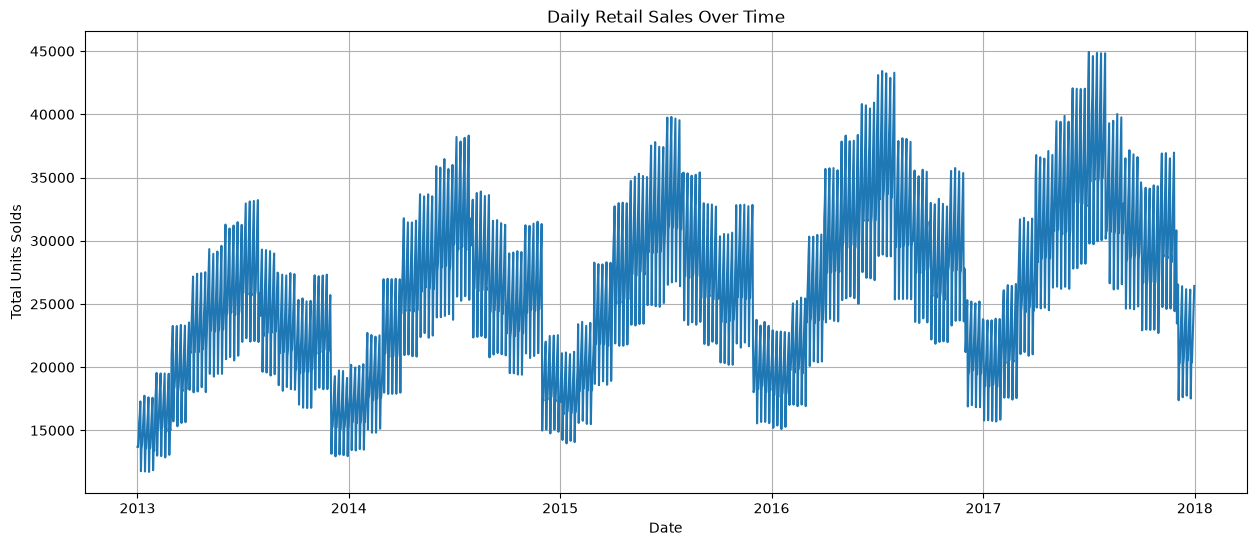

In [6]:
plt.figure(figsize=(15,6))

plt.plot(
    daily_sales.index,
    daily_sales.values
)

plt.title("Daily Retail Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Units Solds")

plt.grid(True)
plt.show()

In [7]:
daily_sales_7d = daily_sales.rolling(window=7).mean()
daily_sales_30d = daily_sales.rolling(window=30).mean()

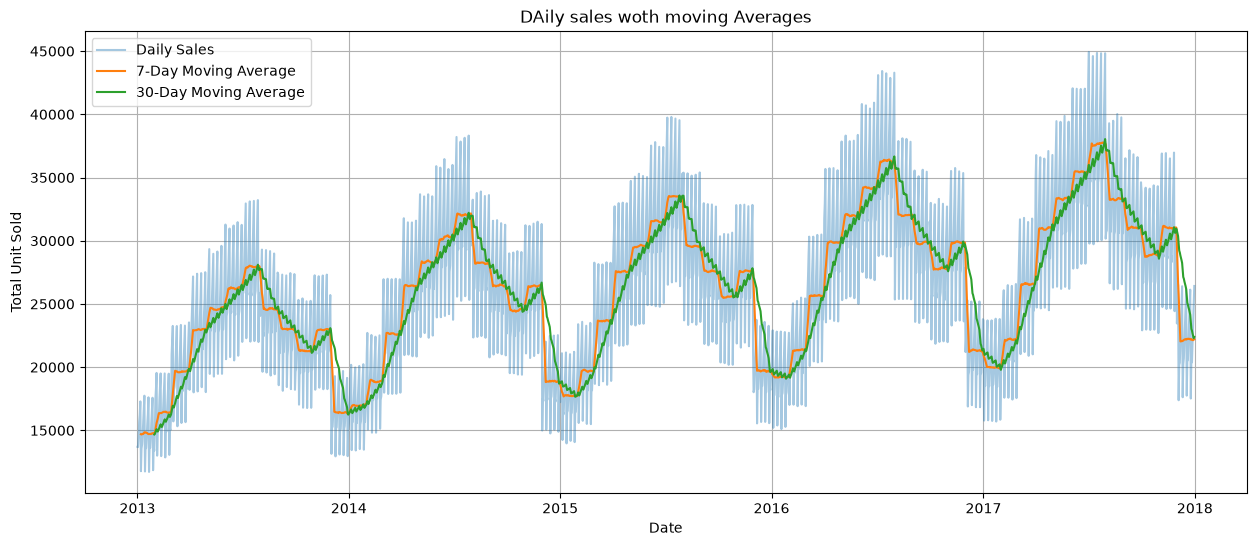

In [11]:
plt.figure(figsize=(15,6))

plt.plot(
    daily_sales.index,
    daily_sales.values,
    label="Daily Sales",
    alpha=0.4
)

plt.plot(
    daily_sales_7d.index,
    daily_sales_7d.values,
    label = "7-Day Moving Average"
)

plt.plot(
    daily_sales_30d.index,
    daily_sales_30d.values,
    label="30-Day Moving Average"
)

plt.title("DAily sales woth moving Averages")
plt.xlabel("Date")
plt.ylabel("Total Unit Sold")

plt.legend()
plt.grid(True)

plt.show()

In [12]:
print("Total Daily obsevation:",len(daily_sales))

print("Frist date:",daily_sales.index.min())
print("Last date:",daily_sales.index.max())

print("FRequency between observation:")
print(daily_sales.index.to_series().diff().value_counts().head())

Total Daily obsevation: 1826
Frist date: 2013-01-01 00:00:00
Last date: 2017-12-31 00:00:00
FRequency between observation:
date
1 days    1825
Name: count, dtype: int64


In [13]:
#learn till this 
"""
Daily sales flutuate siginificanlty
Daily fluctutaions make the graph look noise 
Moving averages help smooth the noise 
the 7 day average captures shorter term changes 
the 30 day average revaels broder trends """

'\nDaily sales flutuate siginificanlty\nDaily fluctutaions make the graph look noise \nMoving averages help smooth the noise \nthe 7 day average captures shorter term changes \nthe 30 day average revaels broder trends '